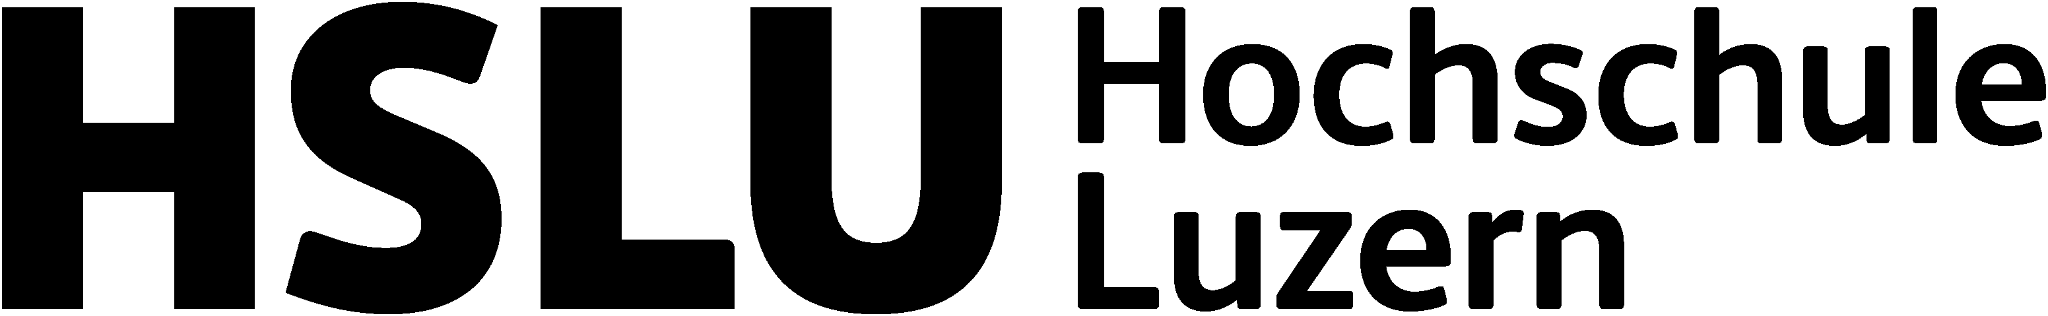

# From AI News to a Tiny Knowledge Graph

**Computational Language Technologies · MSc Applied Data Science and AI**  
**Morning 1 companion tutorial · Courses 2 and 3**

<div style="border-left:6px solid #D94F4F; padding:10px 14px; background:#F8F4EE; margin:18px 0;">
<b>Guiding question</b><br>
How do we turn raw language into explicit, traceable, machine-processable claims—without losing the evidence?
</div>

This is a **single, self-contained tutorial notebook**. The core path requires **no API key** and uses a small, explicitly fictional AI-media corpus. Every important intermediate representation remains inspectable: source text, sentence offsets, entity mentions, canonical IDs, claims, provenance, validation results, and graph edges.

## Learning objectives

By the end, you should be able to:

1. preserve raw text and metadata while creating derived analytical views;
2. inspect sentence boundaries, corpus shape, and near-duplicates before extraction;
3. define a domain schema that follows project questions;
4. extract entity mentions with offsets and map them to canonical entity IDs;
5. distinguish co-occurrence, relation candidates, evidence-bearing claims, and events;
6. construct and query a small typed, directed knowledge graph;
7. evaluate extraction decisions and use errors to propose one targeted improvement.

<div style="border-left:6px solid #4D7C8A; padding:10px 14px; background:#EEF5F6;">
<b>Boundary with the deep-learning part of the course</b><br>
We use a transparent rule-based baseline so that the data contract and failure modes stay visible. A neural NER system or an LLM can later replace the candidate generator; the representation, validation, provenance, and evaluation responsibilities remain.
</div>

## Two ways to use the notebook

| Path | Approx. time | What to run |
|---|---:|---|
| **Live core path** | 30–35 min | Cells marked **CORE**; skim the activities and optional diagnostics |
| **Complete tutorial** | 60–75 min | Run everything, answer the checkpoints, and inspect the extension |

**Notation used below**

- 🔴 **CORE** — essential route from text to graph
- ◇ **CHECKPOINT** — pause, predict, or interpret before running the next cell
- ↗ **EXTENSION** — useful after class or when time permits

All organisations, products, people, publications, URLs, and claims in the corpus are **synthetic**. They are designed to expose realistic NLP problems; they are not news reports.

<details>
<summary><b>Suggested 35-minute live route</b></summary>

| Minute | Focus | Live action |
|---:|---|---|
| 0–5 | Source audit | Load corpus; predict distortions; inspect near-duplicates |
| 5–8 | Segmentation | Show evidence offsets and the round-trip assertion |
| 8–11 | Schema | Read one track question into entity/relation types |
| 11–17 | NER | Run baseline; find and add `Vertex V9` |
| 17–21 | Linking | Contrast mention, canonical ID, ambiguity, and NIL |
| 21–27 | Claims | Inspect accepted and withheld relation candidates |
| 27–31 | Graph | Compare co-occurrence with typed edges; run the path query |
| 31–35 | Evaluation | Read precision/recall; formulate the targeted hypothesis |

Skim the full event table and deterministic validation code during the live route; students can run those cells afterwards. Precomputed outputs are retained, so the tutorial can still be discussed if package installation or class timing becomes tight.
</details>

## The representation journey

```text
source document
  → sentence spans
    → entity mentions
      → canonical entities
        → relation/event candidates
          → validated claims + provenance
            → typed knowledge graph
```

The arrow does **not** mean that uncertainty disappears. Each step adds commitments, and each commitment can introduce a new class of error. Our design goal is therefore not merely to produce triples; it is to preserve enough evidence to audit how each triple was produced.

# 0 · Environment and reproducibility

🔴 **CORE**

In [1]:
# Install only packages that are missing. In a standard Google Colab runtime,
# this cell normally installs spaCy and/or NetworkX once.
import importlib.util
import subprocess
import sys

REQUIRED = {
    "pandas": "pandas>=2.0",
    "numpy": "numpy>=1.24",
    "sklearn": "scikit-learn>=1.3",
    "spacy": "spacy>=3.7,<4",
    "networkx": "networkx>=3.2",
    "matplotlib": "matplotlib>=3.7",
    "pydantic": "pydantic>=2.0,<3",
}

missing = [spec for module, spec in REQUIRED.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already available.")

All required packages are already available.


In [2]:
from __future__ import annotations

import hashlib
import json
import re
from collections import Counter, defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import spacy
from IPython.display import HTML, Markdown, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

PALETTE = {
    "ink": "#17212B",
    "coral": "#D95D4F",
    "teal": "#3D7C83",
    "gold": "#C89B3C",
    "slate": "#6C7A89",
    "paper": "#F8F4EE",
}

print(f"Python {sys.version.split()[0]}")
print(f"pandas {pd.__version__} · spaCy {spacy.__version__} · NetworkX {nx.__version__}")

Python 3.12.14
pandas 2.2.3 · spaCy 3.8.16 · NetworkX 3.6.1


# 1 · Inspect the source before transforming it

🔴 **CORE · Course 2 reinforcement**

A useful unit is not only a text string. It is a **document package**:

- source-faithful text;
- a stable document ID;
- title, publisher, publication time, topic track, and source URL;
- derived views that can be regenerated.

We keep the raw text unchanged and compute hashes, sentence spans, tokens, mentions, and claims in separate tables. This is what makes later evidence coordinates reproducible.

In [3]:
# Explicitly synthetic AI-media corpus. The texts are fictional teaching data.
documents = [
    {
        "doc_id": "D001",
        "title": "Helios-3 public preview scheduled for October",
        "source": "AI Ledger",
        "published_at": "2026-09-14",
        "track": "Foundation Models",
        "source_url": "https://example.org/ai-ledger/d001",
        "text": (
            "Orion Labs said Helios-3 will enter public preview in October 2026. "
            "The model trains on Atlas X accelerators supplied by Northstar Systems. "
            "The announcement was made in Zurich."
        ),
    },
    {
        "doc_id": "D002",
        "title": "Atlas X2 unveiled for datacentre inference",
        "source": "Compute Wire",
        "published_at": "2026-09-13",
        "track": "Hardware and Infrastructure",
        "source_url": "https://example.org/compute-wire/d002",
        "text": (
            "Northstar Systems Inc. unveiled Atlas X2 in Zurich on 12 September 2026. "
            "Orion Labs said it is evaluating the accelerator for Helios services, "
            "but has not selected it for Helios-3."
        ),
    },
    {
        "doc_id": "D003",
        "title": "Nebula introduces AgentMesh",
        "source": "Agentic Web Review",
        "published_at": "2026-09-12",
        "track": "Agentic Web",
        "source_url": "https://example.org/agentic-web/d003",
        "text": (
            "Nebula introduced AgentMesh, a protocol that lets software agents call Helios tools. "
            "Kestrel Agent supports AgentMesh and connects to Helios-3 through an audited gateway."
        ),
    },
    {
        "doc_id": "D004",
        "title": "Orion denies early Helios-3 release",
        "source": "Model Monitor",
        "published_at": "2026-09-11",
        "track": "Foundation Models",
        "source_url": "https://example.org/model-monitor/d004",
        "text": (
            "Orion Labs denied that Helios-3 had been released. "
            "Public preview remains planned for October 2026."
        ),
    },
    {
        "doc_id": "D005",
        "title": "Analysts compare accelerator platforms",
        "source": "Compute Brief",
        "published_at": "2026-09-10",
        "track": "Hardware and Infrastructure",
        "source_url": "https://example.org/compute-brief/d005",
        "text": (
            "Analysts compared Atlas X with Vertex V9. "
            "The report did not state that Orion Labs used Vertex V9 for Helios-3."
        ),
    },
    {
        "doc_id": "D006",
        "title": "Atlas Cloud expands private model hosting",
        "source": "Infrastructure Today",
        "published_at": "2026-09-09",
        "track": "Hardware and Infrastructure",
        "source_url": "https://example.org/infrastructure-today/d006",
        "text": (
            "Northstar Systems operates Atlas Cloud in Basel. "
            "The service uses Atlas X accelerators and hosts a private Helios-2 deployment for Acme Bank."
        ),
    },
    {
        "doc_id": "D007",
        "title": "Helios-3 preview set for October",
        "source": "Syndicated AI Desk",
        "published_at": "2026-09-14",
        "track": "Foundation Models",
        "source_url": "https://example.org/syndicated-ai/d007",
        "text": (
            "Orion Labs said Helios-3 will enter a public preview in October 2026. "
            "It trains on Atlas X accelerators supplied by Northstar Systems. "
            "The statement came from Zurich."
        ),
    },
    {
        "doc_id": "D008",
        "title": "Orion browser agent adopts AgentMesh",
        "source": "Agent Stack",
        "published_at": "2026-09-08",
        "track": "Agentic Web",
        "source_url": "https://example.org/agent-stack/d008",
        "text": (
            "Orion, a browser automation agent from Quanta Works, implemented the AgentMesh protocol. "
            "It is unrelated to Orion Labs."
        ),
    },
    {
        "doc_id": "D009",
        "title": "AgentMesh 1.1 specification published",
        "source": "Protocol Watch",
        "published_at": "2026-09-10",
        "track": "Agentic Web",
        "source_url": "https://example.org/protocol-watch/d009",
        "text": (
            "Nebula and Quanta Works published the AgentMesh 1.1 specification on 10 September 2026. "
            "Kestrel Agent continues to support the protocol."
        ),
    },
    {
        "doc_id": "D010",
        "title": "Helios-2 retirement begins migration period",
        "source": "Model Monitor",
        "published_at": "2026-09-02",
        "track": "Foundation Models",
        "source_url": "https://example.org/model-monitor/d010",
        "text": (
            "Orion Labs retired Helios-2 on 1 September 2026. "
            "Customers were asked to migrate to Helios-3, which had not yet entered public preview."
        ),
    },
    {
        "doc_id": "D011",
        "title": "Atlas X supply agreement enters second year",
        "source": "Compute Wire",
        "published_at": "2026-09-01",
        "track": "Hardware and Infrastructure",
        "source_url": "https://example.org/compute-wire/d011",
        "text": (
            "Northstar Systems supplies Atlas X accelerators to Orion Labs under a three-year agreement "
            "announced in 2025."
        ),
    },
    {
        "doc_id": "D012",
        "title": "Unsupported accelerator claim circulates",
        "source": "Signal Check",
        "published_at": "2026-09-01",
        "track": "Agentic Web",
        "source_url": "https://example.org/signal-check/d012",
        "text": (
            "Lumen Institute reported that Kestrel Agent uses Vertex V9. "
            "No source document or spokesperson supported the claim."
        ),
    },
]

docs = pd.DataFrame(documents)
docs["published_at"] = pd.to_datetime(docs["published_at"])
docs["raw_sha256"] = docs["text"].map(
    lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
)

display(docs[["doc_id", "published_at", "track", "source", "title"]])

,doc_id,published_at,track,source,title
0,D001,2026-09-14,Foundation Models,AI Ledger,Helios-3 public preview scheduled for October
1,D002,2026-09-13,Hardware and Infrastructure,Compute Wire,Atlas X2 unveiled for datacentre inference
2,D003,2026-09-12,Agentic Web,Agentic Web Review,Nebula introduces AgentMesh
3,D004,2026-09-11,Foundation Models,Model Monitor,Orion denies early Helios-3 release
4,D005,2026-09-10,Hardware and Infrastructure,Compute Brief,Analysts compare accelerator platforms
5,D006,2026-09-09,Hardware and Infrastructure,Infrastructure Today,Atlas Cloud expands private model hosting
6,D007,2026-09-14,Foundation Models,Syndicated AI Desk,Helios-3 preview set for October
7,D008,2026-09-08,Agentic Web,Agent Stack,Orion browser agent adopts AgentMesh
8,D009,2026-09-10,Agentic Web,Protocol Watch,AgentMesh 1.1 specification published
9,D010,2026-09-02,Foundation Models,Model Monitor,Helios-2 retirement begins migration period


◇ **CHECKPOINT — before calculating anything**

What could distort entity and relation counts in this collection?

Consider at least four possibilities: missing metadata, article length, duplicated reporting, uneven topic coverage, segmentation errors, publication dates, and ambiguous names. Then run the audit.

In [4]:
docs["n_characters"] = docs["text"].str.len()
docs["n_whitespace_tokens"] = docs["text"].str.split().str.len()

audit = pd.DataFrame({
    "documents": [len(docs)],
    "missing_text": [int(docs["text"].isna().sum())],
    "duplicate_doc_ids": [int(docs["doc_id"].duplicated().sum())],
    "exact_duplicate_texts": [int(docs["text"].duplicated().sum())],
    "min_tokens": [int(docs["n_whitespace_tokens"].min())],
    "median_tokens": [float(docs["n_whitespace_tokens"].median())],
    "max_tokens": [int(docs["n_whitespace_tokens"].max())],
})

display(audit)
display(pd.crosstab(docs["track"], docs["published_at"].dt.date))

,documents,missing_text,duplicate_doc_ids,exact_duplicate_texts,min_tokens,median_tokens,max_tokens
0,12,0,0,0,15,21.0,30


published_at,2026-09-01,2026-09-02,2026-09-08,2026-09-09,2026-09-10,2026-09-11,2026-09-12,2026-09-13,2026-09-14
track,,,,,,,,,
Agentic Web,1,0,1,0,1,0,1,0,0
Foundation Models,0,1,0,0,0,1,0,0,2
Hardware and Infrastructure,1,0,0,1,1,0,0,1,0


The audit finds no exact duplicates—but exact matching is too weak for syndicated or lightly rewritten articles. Near-duplicates matter because repeated stories can inflate entity frequencies, relation counts, and apparent trends.

We use word and bigram TF–IDF only as a compact diagnostic. It is not a universal duplicate detector, and its threshold must be calibrated on the corpus.

In [5]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), stop_words="english")
matrix = vectorizer.fit_transform(docs["text"])
similarities = cosine_similarity(matrix)

pairs = []
for i, j in combinations(range(len(docs)), 2):
    pairs.append({
        "doc_a": docs.loc[i, "doc_id"],
        "doc_b": docs.loc[j, "doc_id"],
        "cosine_similarity": round(float(similarities[i, j]), 3),
    })

near_duplicates = (
    pd.DataFrame(pairs)
    .sort_values("cosine_similarity", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
display(near_duplicates)

,doc_a,doc_b,cosine_similarity
0,D001,D007,0.718
1,D001,D004,0.213
2,D004,D007,0.213
3,D001,D002,0.196
4,D002,D007,0.196
5,D008,D009,0.192
6,D005,D012,0.182
7,D004,D010,0.172


**Interpretation.** D001 and D007 are deliberately near-duplicates. Do not automatically delete one: two independent sources may strengthen provenance, while syndicated copies may merely repeat the same reporting. A production system should record the duplicate cluster and decide how it affects each downstream analysis.

**Capstone transfer:** keep a source-faithful document table plus a derived duplicate-cluster field. Report whether counts are document-level, source-level, or de-duplicated.

# 2 · Segment documents while preserving offsets

🔴 **CORE · Course 2 → Course 3 bridge**

Sentence segmentation creates candidate evidence units. It is not only a formatting convenience: relation extraction often assumes that two mentions in the same sentence may participate in one claim.

We use spaCy's lightweight punctuation-based `sentencizer`; no statistical model is downloaded. The important output is the contract:

`doc_id + sentence_id + start_char + end_char + sentence_text`

Offsets refer to the unchanged document text, so every extracted object can point back to evidence.

In [6]:
segmenter = spacy.blank("en")
segmenter.add_pipe("sentencizer")

sentence_rows = []
for row in docs.itertuples(index=False):
    parsed = segmenter(row.text)
    for local_index, sent in enumerate(parsed.sents, start=1):
        sentence_rows.append({
            "sentence_id": f"{row.doc_id}-S{local_index:02d}",
            "doc_id": row.doc_id,
            "sentence_index": local_index,
            "start_char": sent.start_char,
            "end_char": sent.end_char,
            "sentence_text": sent.text,
        })

sentences = pd.DataFrame(sentence_rows)
display(sentences.head(10))

,sentence_id,doc_id,sentence_index,start_char,end_char,sentence_text
0,D001-S01,D001,1,0,67,Orion Labs said Helios-3 will enter public preview in October 2026.
1,D001-S02,D001,2,68,139,The model trains on Atlas X accelerators supplied by Northstar Systems.
2,D001-S03,D001,3,140,176,The announcement was made in Zurich.
3,D002-S01,D002,1,0,72,Northstar Systems Inc. unveiled Atlas X2 in Zurich on 12 September 2026.
4,D002-S02,D002,2,73,180,"Orion Labs said it is evaluating the accelerator for Helios services, but has not selected it for Helios-3."
5,D003-S01,D003,1,0,84,"Nebula introduced AgentMesh, a protocol that lets software agents call Helios tools."
6,D003-S02,D003,2,85,170,Kestrel Agent supports AgentMesh and connects to Helios-3 through an audited gateway.
7,D004-S01,D004,1,0,50,Orion Labs denied that Helios-3 had been released.
8,D004-S02,D004,2,51,99,Public preview remains planned for October 2026.
9,D005-S01,D005,1,0,41,Analysts compared Atlas X with Vertex V9.


In [7]:
# Evidence-coordinate test: the stored offsets must reproduce the sentence exactly.
text_by_doc = docs.set_index("doc_id")["text"].to_dict()
sentences["offsets_reproduce_text"] = sentences.apply(
    lambda r: text_by_doc[r.doc_id][r.start_char:r.end_char] == r.sentence_text,
    axis=1,
)

assert sentences["offsets_reproduce_text"].all()
display(
    sentences.groupby("doc_id")
    .agg(n_sentences=("sentence_id", "size"), all_offsets_valid=("offsets_reproduce_text", "all"))
    .head()
)

,n_sentences,all_offsets_valid
doc_id,,
D001,3,True
D002,2,True
D003,2,True
D004,2,True
D005,2,True


◇ **CHECKPOINT**

Inspect D002 and D009. Why might a punctuation-only segmenter still fail on other news pages?

Possible answers: abbreviations, headings without final punctuation, bullet lists, quotations, tables, PDF line breaks, captions, and multilingual punctuation. The correct response is not necessarily “use a larger model”; it is to test boundaries on examples from the actual corpus and preserve the raw text so the decision remains reversible.

In [8]:
display(sentences[sentences["doc_id"].isin(["D002", "D009"])][
    ["sentence_id", "start_char", "end_char", "sentence_text"]
])

,sentence_id,start_char,end_char,sentence_text
3,D002-S01,0,72,Northstar Systems Inc. unveiled Atlas X2 in Zurich on 12 September 2026.
4,D002-S02,73,180,"Orion Labs said it is evaluating the accelerator for Helios services, but has not selected it for Helios-3."
18,D009-S01,0,87,Nebula and Quanta Works published the AgentMesh 1.1 specification on 10 September 2026.
19,D009-S02,88,136,Kestrel Agent continues to support the protocol.


# 3 · Design the schema from the questions

🔴 **CORE**

A schema is a commitment about what the project considers important. Start from the questions—not from whichever labels a convenient model happens to predict.

| Capstone track | Example question | Needed structure |
|---|---|---|
| Hardware & Infrastructure | Which models use which accelerators, supplied by whom? | model → accelerator → organisation |
| Foundation Models | Which organisation announced or retired which model, and when? | organisation → model + event time/status |
| Agentic Web | Which agents support which protocol and connect to which model? | agent → protocol/model |

We keep locations and dates as mention types, but not every mention type must become a graph node. Dates are often better represented as claim/event properties.

In [9]:
ENTITY_TYPES = {
    "ORGANIZATION": "Companies, institutions, and formal organisations",
    "FOUNDATION_MODEL": "Named foundation-model products or versions",
    "ACCELERATOR": "Named accelerator products or versions",
    "AGENT": "Named software agents",
    "PROTOCOL": "Named agent/web protocols or specifications",
    "CLOUD_SERVICE": "Named compute or hosting services",
    "LOCATION": "Named places",
    "DATE": "Explicit temporal expressions",
}

# A predicate is directed. Each signature lists allowed subject/object types.
RELATION_SIGNATURES = {
    "ANNOUNCED_PREVIEW": {("ORGANIZATION", "FOUNDATION_MODEL")},
    "TRAINS_ON": {("FOUNDATION_MODEL", "ACCELERATOR")},
    "SUPPLIED_BY": {("ACCELERATOR", "ORGANIZATION")},
    "INTRODUCED": {("ORGANIZATION", "PROTOCOL")},
    "SUPPORTS_PROTOCOL": {("AGENT", "PROTOCOL")},
    "CONNECTS_TO": {("AGENT", "FOUNDATION_MODEL")},
    "OPERATES": {("ORGANIZATION", "CLOUD_SERVICE")},
    "USES_ACCELERATOR": {("CLOUD_SERVICE", "ACCELERATOR")},
    "HOSTS_MODEL": {("CLOUD_SERVICE", "FOUNDATION_MODEL")},
    "RETIRED": {("ORGANIZATION", "FOUNDATION_MODEL")},
    "IMPLEMENTED_PROTOCOL": {("AGENT", "PROTOCOL")},
}

schema_table = pd.DataFrame([
    {"predicate": predicate,
     "allowed_subject → object": "; ".join(f"{s} → {o}" for s, o in sorted(signatures))}
    for predicate, signatures in RELATION_SIGNATURES.items()
])
display(schema_table)

,predicate,allowed_subject → object
0,ANNOUNCED_PREVIEW,ORGANIZATION → FOUNDATION_MODEL
1,TRAINS_ON,FOUNDATION_MODEL → ACCELERATOR
2,SUPPLIED_BY,ACCELERATOR → ORGANIZATION
3,INTRODUCED,ORGANIZATION → PROTOCOL
4,SUPPORTS_PROTOCOL,AGENT → PROTOCOL
5,CONNECTS_TO,AGENT → FOUNDATION_MODEL
6,OPERATES,ORGANIZATION → CLOUD_SERVICE
7,USES_ACCELERATOR,CLOUD_SERVICE → ACCELERATOR
8,HOSTS_MODEL,CLOUD_SERVICE → FOUNDATION_MODEL
9,RETIRED,ORGANIZATION → FOUNDATION_MODEL


**Important limitation:** the schema excludes many potentially useful claims. D011, for example, describes a supply agreement. We have not defined an agreement entity or a `SUPPLIES_TO` relation. That omission is not a model error; it is a schema-coverage decision that should be documented and revisited against the research questions.

# 4 · Extract entity mentions with a transparent baseline

🔴 **CORE**

Named-entity recognition predicts two things:

1. **where** the mention begins and ends;
2. **which type** the mention has in our schema.

Here an `EntityRuler` performs exact, auditable matching. This is a deliberately modest baseline—not a claim about state-of-the-art NER. It is useful because we can see precisely why each span appears and because domain dictionaries often remain valuable alongside statistical systems.

In [10]:
BASE_PATTERNS = [
    {"label": "ORGANIZATION", "pattern": "Orion Labs"},
    {"label": "ORGANIZATION", "pattern": "Northstar Systems"},
    {"label": "ORGANIZATION", "pattern": "Northstar Systems Inc."},
    {"label": "ORGANIZATION", "pattern": "Nebula"},
    {"label": "ORGANIZATION", "pattern": "Quanta Works"},
    {"label": "ORGANIZATION", "pattern": "Acme Bank"},
    {"label": "ORGANIZATION", "pattern": "Lumen Institute"},
    {"label": "FOUNDATION_MODEL", "pattern": "Helios-3"},
    {"label": "FOUNDATION_MODEL", "pattern": "Helios-2"},
    {"label": "ACCELERATOR", "pattern": "Atlas X"},
    {"label": "ACCELERATOR", "pattern": "Atlas X2"},
    # Vertex V9 is intentionally omitted for the checkpoint below.
    {"label": "AGENT", "pattern": "Kestrel Agent"},
    {"label": "AGENT", "pattern": "Orion"},
    {"label": "PROTOCOL", "pattern": "AgentMesh"},
    {"label": "CLOUD_SERVICE", "pattern": "Atlas Cloud"},
    {"label": "LOCATION", "pattern": "Zurich"},
    {"label": "LOCATION", "pattern": "Basel"},
    {"label": "DATE", "pattern": "October 2026"},
    {"label": "DATE", "pattern": "12 September 2026"},
    {"label": "DATE", "pattern": "10 September 2026"},
    {"label": "DATE", "pattern": "1 September 2026"},
    {"label": "DATE", "pattern": "2025"},
]

def build_entity_pipeline(patterns):
    pipeline = spacy.blank("en")
    ruler = pipeline.add_pipe("entity_ruler", config={"phrase_matcher_attr": "LOWER"})
    ruler.add_patterns(patterns)
    return pipeline

def extract_mentions(document_table, sentence_table, pipeline):
    rows = []
    sentence_groups = {
        doc_id: group.sort_values("start_char").to_dict("records")
        for doc_id, group in sentence_table.groupby("doc_id")
    }
    mention_counter = 1
    for document in document_table.itertuples(index=False):
        parsed = pipeline(document.text)
        for ent in parsed.ents:
            containing_sentence = next(
                s for s in sentence_groups[document.doc_id]
                if s["start_char"] <= ent.start_char and ent.end_char <= s["end_char"]
            )
            rows.append({
                "mention_id": f"M{mention_counter:03d}",
                "doc_id": document.doc_id,
                "sentence_id": containing_sentence["sentence_id"],
                "mention_text": ent.text,
                "entity_type": ent.label_,
                "start_char": ent.start_char,
                "end_char": ent.end_char,
            })
            mention_counter += 1
    return pd.DataFrame(rows)

baseline_nlp = build_entity_pipeline(BASE_PATTERNS)
baseline_mentions = extract_mentions(docs, sentences, baseline_nlp)
display(baseline_mentions.head(15))

,mention_id,doc_id,sentence_id,mention_text,entity_type,start_char,end_char
0,M001,D001,D001-S01,Orion Labs,ORGANIZATION,0,10
1,M002,D001,D001-S01,Helios-3,FOUNDATION_MODEL,16,24
2,M003,D001,D001-S01,October 2026,DATE,54,66
3,M004,D001,D001-S02,Atlas X,ACCELERATOR,88,95
4,M005,D001,D001-S02,Northstar Systems,ORGANIZATION,121,138
5,M006,D001,D001-S03,Zurich,LOCATION,169,175
6,M007,D002,D002-S01,Northstar Systems Inc.,ORGANIZATION,0,22
7,M008,D002,D002-S01,Atlas X2,ACCELERATOR,32,40
8,M009,D002,D002-S01,Zurich,LOCATION,44,50
9,M010,D002,D002-S01,12 September 2026,DATE,54,71


◇ **CHECKPOINT — find the missing domain entity**

D005 and D012 contain `Vertex V9`, but our baseline inventory does not. Confirm the omission, then add one pattern. In a real project, this could come from error analysis, a product catalogue, or an annotation round—not from silently editing the final results.

In [11]:
display(docs.loc[docs["doc_id"].isin(["D005", "D012"]), ["doc_id", "text"]])
display(baseline_mentions[baseline_mentions["doc_id"].isin(["D005", "D012"])])

,doc_id,text
4,D005,Analysts compared Atlas X with Vertex V9. The report did not state that Orion Labs used Vertex V9 for Helios-3.
11,D012,Lumen Institute reported that Kestrel Agent uses Vertex V9. No source document or spokesperson supported the claim.


,mention_id,doc_id,sentence_id,mention_text,entity_type,start_char,end_char
20,M021,D005,D005-S01,Atlas X,ACCELERATOR,18,25
21,M022,D005,D005-S02,Orion Labs,ORGANIZATION,72,82
22,M023,D005,D005-S02,Helios-3,FOUNDATION_MODEL,102,110
52,M053,D012,D012-S01,Lumen Institute,ORGANIZATION,0,15
53,M054,D012,D012-S01,Kestrel Agent,AGENT,30,43


In [12]:
# Solution: extend the candidate generator, then recompute the derived mention table.
EXTENDED_PATTERNS = BASE_PATTERNS + [
    {"label": "ACCELERATOR", "pattern": "Vertex V9"}
]

entity_nlp = build_entity_pipeline(EXTENDED_PATTERNS)
mentions = extract_mentions(docs, sentences, entity_nlp)

display(mentions[mentions["doc_id"].isin(["D005", "D012"])])

,mention_id,doc_id,sentence_id,mention_text,entity_type,start_char,end_char
20,M021,D005,D005-S01,Atlas X,ACCELERATOR,18,25
21,M022,D005,D005-S01,Vertex V9,ACCELERATOR,31,40
22,M023,D005,D005-S02,Orion Labs,ORGANIZATION,72,82
23,M024,D005,D005-S02,Vertex V9,ACCELERATOR,88,97
24,M025,D005,D005-S02,Helios-3,FOUNDATION_MODEL,102,110
54,M055,D012,D012-S01,Lumen Institute,ORGANIZATION,0,15
55,M056,D012,D012-S01,Kestrel Agent,AGENT,30,43
56,M057,D012,D012-S01,Vertex V9,ACCELERATOR,49,58


In [13]:
# Verify mention offsets against immutable source text.
mentions["offsets_reproduce_mention"] = mentions.apply(
    lambda r: text_by_doc[r.doc_id][r.start_char:r.end_char] == r.mention_text,
    axis=1,
)
assert mentions["offsets_reproduce_mention"].all()

mention_summary = (
    mentions.groupby("entity_type")
    .agg(mentions=("mention_id", "size"), documents=("doc_id", "nunique"))
    .sort_values("mentions", ascending=False)
)
display(mention_summary)

,mentions,documents
entity_type,,
ORGANIZATION,19,12
ACCELERATOR,9,7
FOUNDATION_MODEL,9,8
DATE,7,7
LOCATION,4,4
AGENT,4,4
PROTOCOL,4,3
CLOUD_SERVICE,1,1


**What this baseline cannot do well**

- discover unseen names without patterns;
- resolve pronouns such as “the model”, “the service”, “it”, or “the protocol”;
- decide whether a span denotes the organisation *Orion Labs* or the agent *Orion* without reliable context and typing;
- generalise across spelling variation and multilingual mentions;
- infer that a mention is relevant merely because it is capitalised.

A neural or LLM-based extractor may improve candidate coverage, but it does not remove the need for offsets, a schema, entity resolution, evidence checks, and evaluation.

# 5 · Normalize mentions and link entities

🔴 **CORE**

A **mention** is a span in one document. An **entity** is the canonical object to which one or more mentions may refer.

Entity linking therefore needs at least three outcomes:

- a canonical ID when evidence is sufficient;
- an ambiguous candidate set when several entities remain plausible;
- **NIL / unresolved** when the correct entity is not yet in the catalogue.

Treating every surface form as an entity creates duplicates; forcing every mention onto an existing entity silently creates false merges.

In [14]:
entity_catalogue = [
    {"entity_id": "org:orion_labs", "canonical_name": "Orion Labs", "entity_type": "ORGANIZATION",
     "aliases": ["Orion Labs", "Orion Labs Inc.", "Orion"]},
    {"entity_id": "org:northstar_systems", "canonical_name": "Northstar Systems", "entity_type": "ORGANIZATION",
     "aliases": ["Northstar Systems", "Northstar Systems Inc."]},
    {"entity_id": "org:nebula", "canonical_name": "Nebula", "entity_type": "ORGANIZATION",
     "aliases": ["Nebula"]},
    {"entity_id": "org:quanta_works", "canonical_name": "Quanta Works", "entity_type": "ORGANIZATION",
     "aliases": ["Quanta Works"]},
    {"entity_id": "org:acme_bank", "canonical_name": "Acme Bank", "entity_type": "ORGANIZATION",
     "aliases": ["Acme Bank"]},
    {"entity_id": "model:helios_3", "canonical_name": "Helios-3", "entity_type": "FOUNDATION_MODEL",
     "aliases": ["Helios-3", "Helios 3"]},
    {"entity_id": "model:helios_2", "canonical_name": "Helios-2", "entity_type": "FOUNDATION_MODEL",
     "aliases": ["Helios-2", "Helios 2"]},
    {"entity_id": "hardware:atlas_x", "canonical_name": "Atlas X", "entity_type": "ACCELERATOR",
     "aliases": ["Atlas X"]},
    {"entity_id": "hardware:atlas_x2", "canonical_name": "Atlas X2", "entity_type": "ACCELERATOR",
     "aliases": ["Atlas X2"]},
    {"entity_id": "hardware:vertex_v9", "canonical_name": "Vertex V9", "entity_type": "ACCELERATOR",
     "aliases": ["Vertex V9"]},
    {"entity_id": "agent:kestrel", "canonical_name": "Kestrel Agent", "entity_type": "AGENT",
     "aliases": ["Kestrel Agent", "Kestrel"]},
    {"entity_id": "agent:orion_browser", "canonical_name": "Orion", "entity_type": "AGENT",
     "aliases": ["Orion"]},
    {"entity_id": "protocol:agentmesh", "canonical_name": "AgentMesh", "entity_type": "PROTOCOL",
     "aliases": ["AgentMesh", "AgentMesh 1.1"]},
    {"entity_id": "service:atlas_cloud", "canonical_name": "Atlas Cloud", "entity_type": "CLOUD_SERVICE",
     "aliases": ["Atlas Cloud"]},
    {"entity_id": "place:zurich", "canonical_name": "Zurich", "entity_type": "LOCATION",
     "aliases": ["Zurich"]},
    {"entity_id": "place:basel", "canonical_name": "Basel", "entity_type": "LOCATION",
     "aliases": ["Basel"]},
]

entities = pd.DataFrame(entity_catalogue)
display(entities[["entity_id", "canonical_name", "entity_type", "aliases"]])

,entity_id,canonical_name,entity_type,aliases
0,org:orion_labs,Orion Labs,ORGANIZATION,"[Orion Labs, Orion Labs Inc., Orion]"
1,org:northstar_systems,Northstar Systems,ORGANIZATION,"[Northstar Systems, Northstar Systems Inc.]"
2,org:nebula,Nebula,ORGANIZATION,[Nebula]
3,org:quanta_works,Quanta Works,ORGANIZATION,[Quanta Works]
4,org:acme_bank,Acme Bank,ORGANIZATION,[Acme Bank]
5,model:helios_3,Helios-3,FOUNDATION_MODEL,"[Helios-3, Helios 3]"
6,model:helios_2,Helios-2,FOUNDATION_MODEL,"[Helios-2, Helios 2]"
7,hardware:atlas_x,Atlas X,ACCELERATOR,[Atlas X]
8,hardware:atlas_x2,Atlas X2,ACCELERATOR,[Atlas X2]
9,hardware:vertex_v9,Vertex V9,ACCELERATOR,[Vertex V9]


In [15]:
def normalize_surface(text):
    # Normalization is for candidate lookup; the original mention remains untouched.
    return re.sub(r"\s+", " ", text.casefold()).strip(" .,:;()")

alias_index = defaultdict(list)
for entity in entity_catalogue:
    for alias in entity["aliases"]:
        alias_index[normalize_surface(alias)].append(entity)

def link_mention(row):
    # Dates are kept as temporal mentions and later normalized as properties.
    if row.entity_type == "DATE":
        return pd.Series({
            "entity_id": pd.NA,
            "canonical_name": pd.NA,
            "link_status": "ATTRIBUTE_NOT_NODE",
            "candidate_count": 0,
        })

    candidates = alias_index.get(normalize_surface(row.mention_text), [])
    typed = [c for c in candidates if c["entity_type"] == row.entity_type]

    if len(typed) == 1:
        chosen = typed[0]
        return pd.Series({
            "entity_id": chosen["entity_id"],
            "canonical_name": chosen["canonical_name"],
            "link_status": "LINKED",
            "candidate_count": len(candidates),
        })
    if len(typed) > 1:
        return pd.Series({
            "entity_id": pd.NA,
            "canonical_name": pd.NA,
            "link_status": "AMBIGUOUS",
            "candidate_count": len(typed),
        })
    return pd.Series({
        "entity_id": pd.NA,
        "canonical_name": pd.NA,
        "link_status": "NIL",
        "candidate_count": len(candidates),
    })

linked_mentions = pd.concat([mentions, mentions.apply(link_mention, axis=1)], axis=1)
display(linked_mentions.head(20))

,mention_id,doc_id,sentence_id,mention_text,entity_type,start_char,end_char,offsets_reproduce_mention,entity_id,canonical_name,link_status,candidate_count
0,M001,D001,D001-S01,Orion Labs,ORGANIZATION,0,10,True,org:orion_labs,Orion Labs,LINKED,1
1,M002,D001,D001-S01,Helios-3,FOUNDATION_MODEL,16,24,True,model:helios_3,Helios-3,LINKED,1
2,M003,D001,D001-S01,October 2026,DATE,54,66,True,<NA>,<NA>,ATTRIBUTE_NOT_NODE,0
3,M004,D001,D001-S02,Atlas X,ACCELERATOR,88,95,True,hardware:atlas_x,Atlas X,LINKED,1
4,M005,D001,D001-S02,Northstar Systems,ORGANIZATION,121,138,True,org:northstar_systems,Northstar Systems,LINKED,1
5,M006,D001,D001-S03,Zurich,LOCATION,169,175,True,place:zurich,Zurich,LINKED,1
6,M007,D002,D002-S01,Northstar Systems Inc.,ORGANIZATION,0,22,True,org:northstar_systems,Northstar Systems,LINKED,1
7,M008,D002,D002-S01,Atlas X2,ACCELERATOR,32,40,True,hardware:atlas_x2,Atlas X2,LINKED,1
8,M009,D002,D002-S01,Zurich,LOCATION,44,50,True,place:zurich,Zurich,LINKED,1
9,M010,D002,D002-S01,12 September 2026,DATE,54,71,True,<NA>,<NA>,ATTRIBUTE_NOT_NODE,0


In [16]:
# Why type and context matter: the bare string "Orion" has two catalogue candidates.
orion_candidates = pd.DataFrame(alias_index[normalize_surface("Orion")])[
    ["entity_id", "canonical_name", "entity_type"]
]
unresolved = linked_mentions[linked_mentions["link_status"].isin(["NIL", "AMBIGUOUS"])]

display(Markdown("**Candidates for the surface form `Orion` if type is ignored**"))
display(orion_candidates)
display(Markdown("**Mentions that should not be forced onto an existing entity**"))
display(unresolved[["mention_id", "doc_id", "mention_text", "entity_type", "link_status"]])

**Candidates for the surface form `Orion` if type is ignored**

,entity_id,canonical_name,entity_type
0,org:orion_labs,Orion Labs,ORGANIZATION
1,agent:orion_browser,Orion,AGENT


**Mentions that should not be forced onto an existing entity**

,mention_id,doc_id,mention_text,entity_type,link_status
54,M055,D012,Lumen Institute,ORGANIZATION,NIL


`Lumen Institute` receives NIL because it is detected as an organisation but absent from the catalogue. NIL does **not** mean “not an entity”; it means “not confidently linked to a known canonical entity yet.” A capstone workflow should queue such cases for review or catalogue expansion.

For `Orion`, type information makes the agent candidate unique in D008. If the mention had only a generic type—or if context were weaker—the responsible output would be an ambiguous candidate set, not a forced link.

# 6 · Extract relations and events as evidence-bearing records

🔴 **CORE**

Co-occurrence is only proximity. A relation asserts a **typed, directed claim**.

The baseline below uses deliberately visible lexical rules. It follows a conservative sequence:

1. retrieve linked entities in one sentence and apply three narrow, visible discourse rules;
2. look for a relation trigger;
3. apply negation/status guards;
4. create a claim with the full evidence sentence and coordinates;
5. retain rejected candidates with a reason.

The discourse rules carry forward only `the model`, `the service`, and `the accelerator`; they are not general coreference resolution. This is not intended as production-scale relation extraction. It is an inspectable baseline against which a learned or LLM-based method can be compared.

In [17]:
entity_type_by_id = entities.set_index("entity_id")["entity_type"].to_dict()
document_meta = docs.set_index("doc_id").to_dict("index")

linked_by_sentence = {
    sentence_id: group[group["link_status"] == "LINKED"].to_dict("records")
    for sentence_id, group in linked_mentions.groupby("sentence_id")
}

def entity_ids(sentence_id, entity_type):
    return [
        row["entity_id"] for row in linked_by_sentence.get(sentence_id, [])
        if row["entity_type"] == entity_type
    ]

claim_rows = []
rejection_rows = []

def add_claim(sent, subject_id, predicate, object_id, confidence, status="ASSERTED", event_time=None):
    claim_rows.append({
        "subject_id": subject_id,
        "predicate": predicate,
        "object_id": object_id,
        "source_doc_id": sent.doc_id,
        "sentence_id": sent.sentence_id,
        "evidence_text": sent.sentence_text,
        "evidence_start": sent.start_char,
        "evidence_end": sent.end_char,
        "published_at": document_meta[sent.doc_id]["published_at"],
        "event_time": event_time,
        "assertion_status": status,
        "extraction_method": "transparent_lexical_baseline_v1",
        "confidence": confidence,
    })

def reject(sent, candidate, reason):
    rejection_rows.append({
        "source_doc_id": sent.doc_id,
        "sentence_id": sent.sentence_id,
        "candidate": candidate,
        "reason": reason,
        "evidence_text": sent.sentence_text,
    })

# A very small discourse memory repairs only explicit nominal references such as
# "the model", "the service", and "the accelerator". It intentionally does not
# attempt general coreference resolution.
recent_by_doc = defaultdict(dict)

for sent in sentences.itertuples(index=False):
    text = sent.sentence_text
    lower = text.casefold()
    orgs = entity_ids(sent.sentence_id, "ORGANIZATION")
    models = entity_ids(sent.sentence_id, "FOUNDATION_MODEL")
    hardware = entity_ids(sent.sentence_id, "ACCELERATOR")
    agents = entity_ids(sent.sentence_id, "AGENT")
    protocols = entity_ids(sent.sentence_id, "PROTOCOL")
    services = entity_ids(sent.sentence_id, "CLOUD_SERVICE")

    explicit_for_memory = {
        "FOUNDATION_MODEL": list(models),
        "ACCELERATOR": list(hardware),
        "CLOUD_SERVICE": list(services),
    }

    if not models and ("the model" in lower or lower.startswith("it trains")):
        previous = recent_by_doc[sent.doc_id].get("FOUNDATION_MODEL")
        models = [previous] if previous else []
    if not hardware and "the accelerator" in lower:
        previous = recent_by_doc[sent.doc_id].get("ACCELERATOR")
        hardware = [previous] if previous else []
    if not services and "the service" in lower:
        previous = recent_by_doc[sent.doc_id].get("CLOUD_SERVICE")
        services = [previous] if previous else []

    if "will enter" in lower and "public preview" in lower and orgs and models:
        add_claim(sent, orgs[0], "ANNOUNCED_PREVIEW", models[0], 0.96,
                  status="PLANNED", event_time="2026-10")

    if ("trains on" in lower or "it trains on" in lower) and models and hardware:
        add_claim(sent, models[0], "TRAINS_ON", hardware[0], 0.94)

    if "accelerators supplied by" in lower and hardware and orgs:
        add_claim(sent, hardware[0], "SUPPLIED_BY", orgs[-1], 0.95)

    if "introduced" in lower and orgs and protocols:
        add_claim(sent, orgs[0], "INTRODUCED", protocols[0], 0.96)

    if re.search(r"\bsupports\b", lower) and agents and protocols:
        add_claim(sent, agents[0], "SUPPORTS_PROTOCOL", protocols[0], 0.95)

    if "connects to" in lower and agents and models:
        add_claim(sent, agents[0], "CONNECTS_TO", models[0], 0.94)

    if "operates" in lower and orgs and services:
        add_claim(sent, orgs[0], "OPERATES", services[0], 0.96)

    if "service uses" in lower and services and hardware:
        add_claim(sent, services[0], "USES_ACCELERATOR", hardware[0], 0.93)

    if "hosts" in lower and services and models:
        add_claim(sent, services[0], "HOSTS_MODEL", models[0], 0.92)

    if "retired" in lower and orgs and models:
        add_claim(sent, orgs[0], "RETIRED", models[0], 0.97,
                  status="COMPLETED", event_time="2026-09-01")

    if "implemented" in lower and agents and protocols:
        add_claim(sent, agents[0], "IMPLEMENTED_PROTOCOL", protocols[0], 0.95)

    # Explicitly retain high-risk candidates that the baseline refuses to assert.
    if "not selected" in lower and models and hardware:
        reject(sent, f"{models[0]} TRAINS_ON {hardware[0]}",
               "Evaluation is not selection; sentence contains explicit negation.")
    if "did not state" in lower and models and hardware:
        reject(sent, f"{models[0]} TRAINS_ON {hardware[-1]}",
               "The sentence explicitly denies that the source stated this relation.")
    if "denied" in lower and "released" in lower and models:
        reject(sent, f"{models[0]} RELEASED", "Negated event claim.")
    if "no source document" in lower:
        reject(sent, "agent:kestrel USES_ACCELERATOR hardware:vertex_v9",
               "Claim is explicitly unsupported by a source document or spokesperson.")

    for entity_type, ids in explicit_for_memory.items():
        if ids:
            recent_by_doc[sent.doc_id][entity_type] = ids[-1]

claims = pd.DataFrame(claim_rows)
claims.insert(0, "claim_id", [f"C{i:03d}" for i in range(1, len(claims) + 1)])
rejected_candidates = pd.DataFrame(rejection_rows)

display(claims[[
    "claim_id", "subject_id", "predicate", "object_id",
    "source_doc_id", "assertion_status", "confidence"
]])

,claim_id,subject_id,predicate,object_id,source_doc_id,assertion_status,confidence
0,C001,org:orion_labs,ANNOUNCED_PREVIEW,model:helios_3,D001,PLANNED,0.96
1,C002,model:helios_3,TRAINS_ON,hardware:atlas_x,D001,ASSERTED,0.94
2,C003,hardware:atlas_x,SUPPLIED_BY,org:northstar_systems,D001,ASSERTED,0.95
3,C004,org:nebula,INTRODUCED,protocol:agentmesh,D003,ASSERTED,0.96
4,C005,agent:kestrel,SUPPORTS_PROTOCOL,protocol:agentmesh,D003,ASSERTED,0.95
5,C006,agent:kestrel,CONNECTS_TO,model:helios_3,D003,ASSERTED,0.94
6,C007,org:northstar_systems,OPERATES,service:atlas_cloud,D006,ASSERTED,0.96
7,C008,service:atlas_cloud,USES_ACCELERATOR,hardware:atlas_x,D006,ASSERTED,0.93
8,C009,service:atlas_cloud,HOSTS_MODEL,model:helios_2,D006,ASSERTED,0.92
9,C010,org:orion_labs,ANNOUNCED_PREVIEW,model:helios_3,D007,PLANNED,0.96


In [18]:
display(Markdown("**Rejected or withheld candidates**"))
display(rejected_candidates)

**Rejected or withheld candidates**

,source_doc_id,sentence_id,candidate,reason,evidence_text
0,D002,D002-S02,model:helios_3 TRAINS_ON hardware:atlas_x2,Evaluation is not selection; sentence contains explicit negation.,"Orion Labs said it is evaluating the accelerator for Helios services, but has not selected it for Helios-3."
1,D004,D004-S01,model:helios_3 RELEASED,Negated event claim.,Orion Labs denied that Helios-3 had been released.
2,D005,D005-S02,model:helios_3 TRAINS_ON hardware:vertex_v9,The sentence explicitly denies that the source stated this relation.,The report did not state that Orion Labs used Vertex V9 for Helios-3.
3,D012,D012-S02,agent:kestrel USES_ACCELERATOR hardware:vertex_v9,Claim is explicitly unsupported by a source document or spokesperson.,No source document or spokesperson supported the claim.


Notice the asymmetry: a system should be allowed to return **no claim** when the evidence is negative, hypothetical, merely comparative, or unsupported. Maximising the number of triples is not the objective.

D005 is especially useful: `Atlas X` and `Vertex V9` genuinely co-occur, but that fact does not license a product-use relation. D012 contains the surface wording “uses Vertex V9”, yet the following sentence explicitly questions its support. Cross-sentence discourse and source credibility remain open problems for this simple baseline.

## Events need time and status

A triple such as `(Orion Labs, announced, Helios-3)` omits whether the preview is planned, completed, delayed, or denied. For temporal analysis, represent an event with roles and properties rather than hiding everything in one edge label.

In [19]:
event_rows = [
    {
        "event_id": "E001", "event_type": "PUBLIC_PREVIEW",
        "actor_id": "org:orion_labs", "artifact_id": "model:helios_3",
        "event_time": "2026-10", "event_status": "PLANNED",
        "source_doc_id": "D001", "sentence_id": "D001-S01",
        "trigger": "will enter public preview",
    },
    {
        "event_id": "E002", "event_type": "RELEASE",
        "actor_id": "org:orion_labs", "artifact_id": "model:helios_3",
        "event_time": None, "event_status": "NEGATED",
        "source_doc_id": "D004", "sentence_id": "D004-S01",
        "trigger": "denied ... had been released",
    },
    {
        "event_id": "E003", "event_type": "RETIREMENT",
        "actor_id": "org:orion_labs", "artifact_id": "model:helios_2",
        "event_time": "2026-09-01", "event_status": "COMPLETED",
        "source_doc_id": "D010", "sentence_id": "D010-S01",
        "trigger": "retired",
    },
    {
        "event_id": "E004", "event_type": "PRODUCT_UNVEILING",
        "actor_id": "org:northstar_systems", "artifact_id": "hardware:atlas_x2",
        "event_time": "2026-09-12", "event_status": "COMPLETED",
        "source_doc_id": "D002", "sentence_id": "D002-S01",
        "trigger": "unveiled",
    },
]
events = pd.DataFrame(event_rows)
display(events)

,event_id,event_type,actor_id,artifact_id,event_time,event_status,source_doc_id,sentence_id,trigger
0,E001,PUBLIC_PREVIEW,org:orion_labs,model:helios_3,2026-10,PLANNED,D001,D001-S01,will enter public preview
1,E002,RELEASE,org:orion_labs,model:helios_3,None,NEGATED,D004,D004-S01,denied ... had been released
2,E003,RETIREMENT,org:orion_labs,model:helios_2,2026-09-01,COMPLETED,D010,D010-S01,retired
3,E004,PRODUCT_UNVEILING,org:northstar_systems,hardware:atlas_x2,2026-09-12,COMPLETED,D002,D002-S01,unveiled


◇ **CHECKPOINT**

Why is `published_at` different from `event_time`?

A story published on 14 September may describe a preview planned for October or an agreement announced in 2025. Conflating publication time and event time creates false trend lines and temporal contradictions—exactly the kind of error that later harms temporally grounded RAG.

# 7 · Validate syntax, schema, evidence, and semantics

🔴 **CORE**

“Valid JSON” is only the first layer of validity.

| Layer | Question |
|---|---|
| Parse | Can the record be read? |
| Schema | Are required fields and allowed labels present? |
| Type | Does the predicate allow these entity types? |
| Evidence | Do the coordinates reproduce the claimed evidence? |
| Semantic support | Does the evidence actually express the claim? |

The first four can be checked largely deterministically. Semantic support still requires task-specific rules, review, or an evaluated model.

In [20]:
def validate_claim(row):
    errors = []
    if row.predicate not in RELATION_SIGNATURES:
        errors.append("unknown_predicate")
        return errors

    subject_type = entity_type_by_id.get(row.subject_id)
    object_type = entity_type_by_id.get(row.object_id)
    if (subject_type, object_type) not in RELATION_SIGNATURES[row.predicate]:
        errors.append("type_signature_violation")

    source_text = text_by_doc[row.source_doc_id]
    recovered = source_text[row.evidence_start:row.evidence_end]
    if recovered != row.evidence_text:
        errors.append("evidence_offset_mismatch")

    if not (0.0 <= float(row.confidence) <= 1.0):
        errors.append("confidence_out_of_range")

    return errors

claims["validation_errors"] = claims.apply(validate_claim, axis=1)
claims["validation_status"] = claims["validation_errors"].map(
    lambda errors: "PASS" if not errors else "FAIL"
)

display(claims[["claim_id", "predicate", "validation_status", "validation_errors"]])
assert (claims["validation_status"] == "PASS").all()

,claim_id,predicate,validation_status,validation_errors
0,C001,ANNOUNCED_PREVIEW,PASS,[]
1,C002,TRAINS_ON,PASS,[]
2,C003,SUPPLIED_BY,PASS,[]
3,C004,INTRODUCED,PASS,[]
4,C005,SUPPORTS_PROTOCOL,PASS,[]
5,C006,CONNECTS_TO,PASS,[]
6,C007,OPERATES,PASS,[]
7,C008,USES_ACCELERATOR,PASS,[]
8,C009,HOSTS_MODEL,PASS,[]
9,C010,ANNOUNCED_PREVIEW,PASS,[]


Passing these checks does **not** prove that a claim is true. It proves that the record is internally well-formed, type-compatible, and traceable to a span. The source itself may be wrong, duplicated, stale, or contradicted elsewhere. This is why provenance and temporal information belong in the claim record rather than being added after graph construction.

# 8 · Compare a co-occurrence graph with a knowledge graph

🔴 **CORE**

An entity co-occurrence graph answers: **which linked entities appear in the same sentence?**

A knowledge graph answers: **which typed, directed claims have evidence?**

Both can be useful, but they are not interchangeable. The comparison below uses the same entity mentions so that the difference comes from edge semantics—not from a different corpus.

In [21]:
# 1) Undirected co-occurrence graph
co_graph = nx.Graph()
for entity in entity_catalogue:
    co_graph.add_node(entity["entity_id"],
                      label=entity["canonical_name"],
                      entity_type=entity["entity_type"])

for sentence_id, group in linked_mentions.groupby("sentence_id"):
    ids = sorted(set(group.loc[group["link_status"] == "LINKED", "entity_id"].dropna()))
    for left, right in combinations(ids, 2):
        if co_graph.has_edge(left, right):
            co_graph[left][right]["weight"] += 1
            co_graph[left][right]["sentence_ids"].append(sentence_id)
        else:
            co_graph.add_edge(left, right, weight=1, sentence_ids=[sentence_id])

# 2) Directed typed multigraph: parallel edges preserve multiple evidence records.
kg = nx.MultiDiGraph()
for entity in entity_catalogue:
    kg.add_node(entity["entity_id"],
                label=entity["canonical_name"],
                entity_type=entity["entity_type"])

for claim in claims.itertuples(index=False):
    if claim.validation_status == "PASS":
        kg.add_edge(
            claim.subject_id,
            claim.object_id,
            key=claim.claim_id,
            predicate=claim.predicate,
            claim_id=claim.claim_id,
            source_doc_id=claim.source_doc_id,
            sentence_id=claim.sentence_id,
            evidence_text=claim.evidence_text,
            published_at=str(claim.published_at.date()),
            event_time=claim.event_time,
            assertion_status=claim.assertion_status,
            confidence=float(claim.confidence),
        )

graph_summary = pd.DataFrame([
    {"graph": "Entity co-occurrence", "directed": False,
     "nodes": co_graph.number_of_nodes(), "edges": co_graph.number_of_edges(),
     "edge meaning": "shared sentence"},
    {"graph": "Knowledge graph", "directed": True,
     "nodes": kg.number_of_nodes(), "edges": kg.number_of_edges(),
     "edge meaning": "typed claim with evidence"},
])
display(graph_summary)

,graph,directed,nodes,edges,edge meaning
0,Entity co-occurrence,False,16,26,shared sentence
1,Knowledge graph,True,16,14,typed claim with evidence


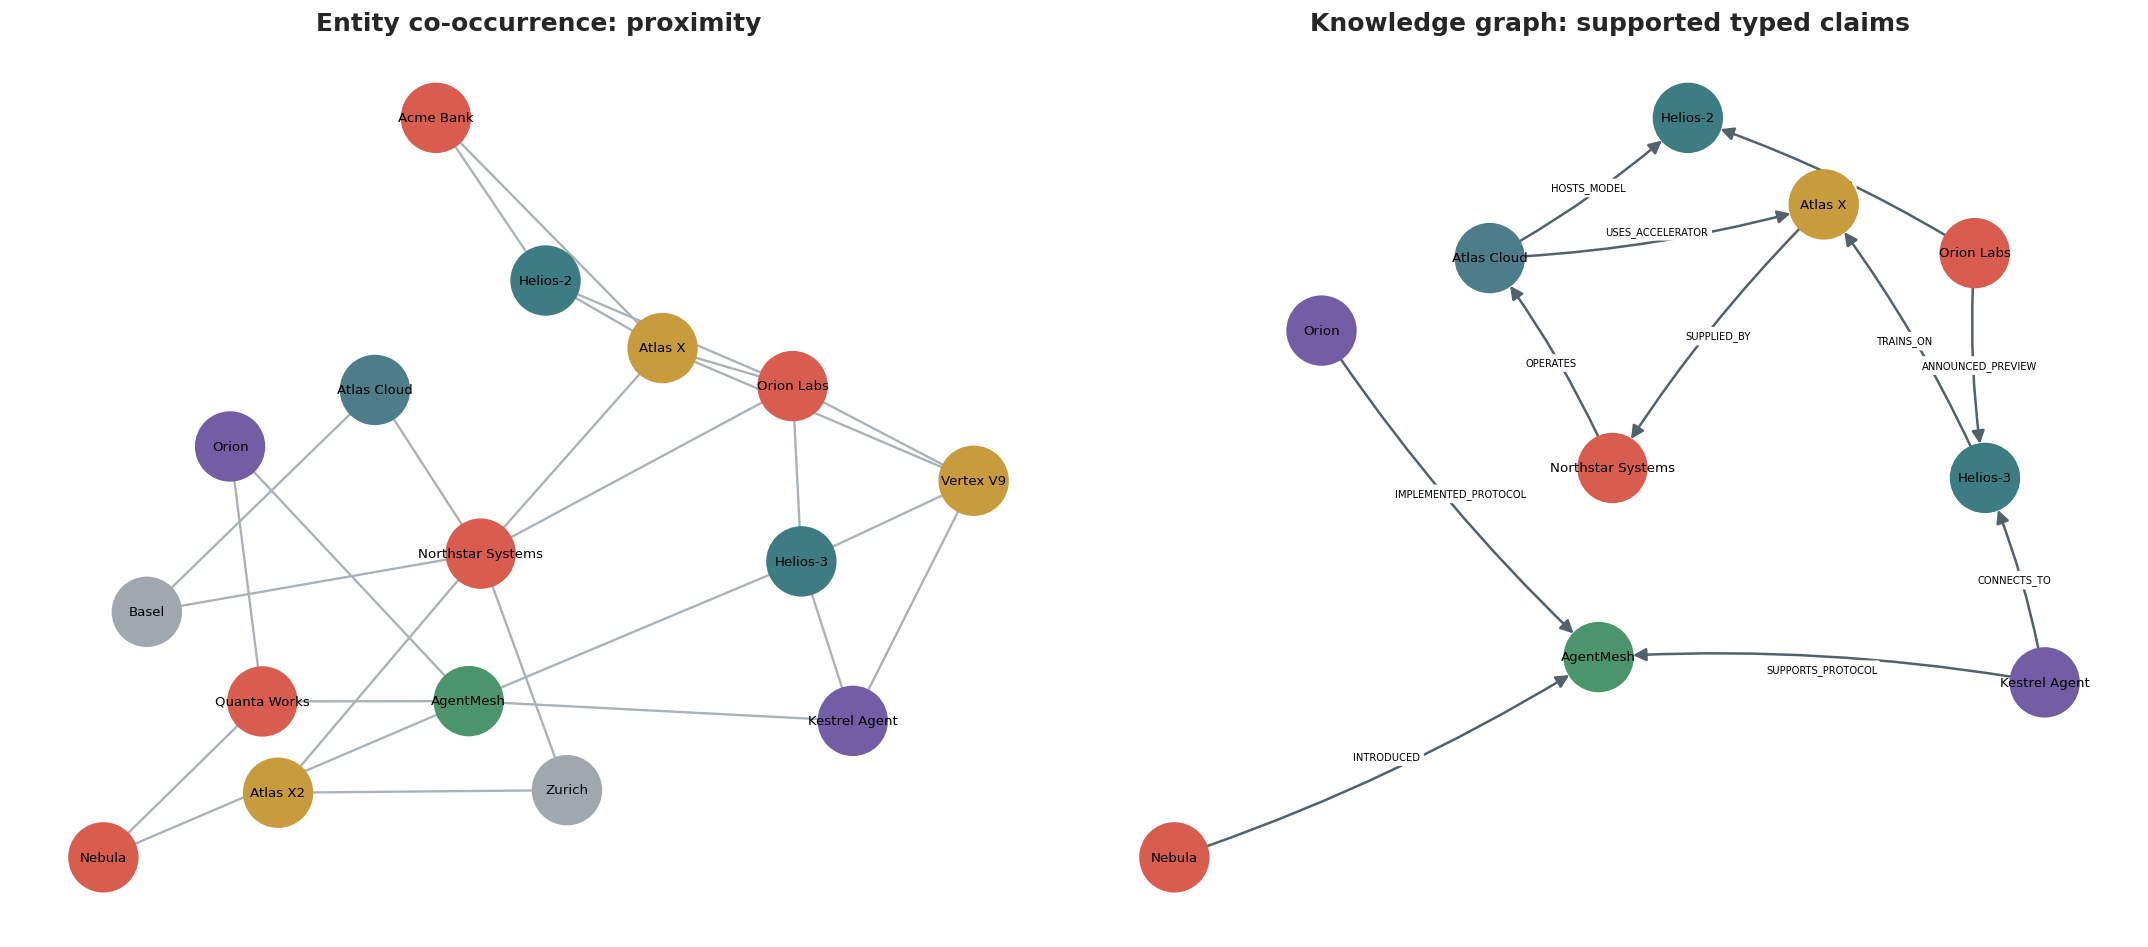

In [22]:
# A compact visual comparison. Unconnected catalogue nodes are hidden for readability.
TYPE_COLORS = {
    "ORGANIZATION": "#D95D4F",
    "FOUNDATION_MODEL": "#3D7C83",
    "ACCELERATOR": "#C89B3C",
    "AGENT": "#735DA5",
    "PROTOCOL": "#4C956C",
    "CLOUD_SERVICE": "#4D7C8A",
    "LOCATION": "#A0A7AE",
}

active_nodes = sorted(set(co_graph.nodes()) - set(nx.isolates(co_graph)))
co_view = co_graph.subgraph(active_nodes).copy()
kg_active_nodes = sorted(set(kg.nodes()) - set(nx.isolates(kg)))
kg_view = kg.subgraph(kg_active_nodes).copy()

all_active = sorted(set(active_nodes) | set(kg_active_nodes))
layout_base = nx.Graph()
layout_base.add_nodes_from(all_active)
layout_base.add_edges_from(co_view.edges())
layout_base.add_edges_from((u, v) for u, v, _ in kg_view.edges(keys=True))
pos = nx.spring_layout(layout_base, seed=11, k=0.9)

def node_colours(graph):
    return [TYPE_COLORS.get(graph.nodes[n].get("entity_type"), "#A0A7AE") for n in graph.nodes()]

labels = {n: kg.nodes[n].get("label", n) for n in all_active}
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

nx.draw_networkx(
    co_view, pos={n: pos[n] for n in co_view.nodes()}, ax=axes[0],
    labels={n: labels[n] for n in co_view.nodes()},
    node_color=node_colours(co_view), node_size=1700,
    font_size=8, edge_color="#AAB2B8", width=1.4,
)
axes[0].set_title("Entity co-occurrence: proximity", fontsize=15, weight="bold")
axes[0].axis("off")

# Collapse parallel KG edges only for drawing; the MultiDiGraph still preserves them.
kg_draw = nx.DiGraph()
for u, v, data in kg_view.edges(data=True):
    label = data["predicate"]
    if kg_draw.has_edge(u, v):
        existing = set(kg_draw[u][v]["label"].split(" / "))
        existing.add(label)
        kg_draw[u][v]["label"] = " / ".join(sorted(existing))
    else:
        kg_draw.add_edge(u, v, label=label)
for n in kg_view.nodes():
    kg_draw.add_node(n, **kg_view.nodes[n])

nx.draw_networkx(
    kg_draw, pos={n: pos[n] for n in kg_draw.nodes()}, ax=axes[1],
    labels={n: labels[n] for n in kg_draw.nodes()},
    node_color=node_colours(kg_draw), node_size=1700,
    font_size=8, edge_color="#53616B", width=1.5,
    arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.06",
)
nx.draw_networkx_edge_labels(
    kg_draw, pos={n: pos[n] for n in kg_draw.nodes()}, ax=axes[1],
    edge_labels=nx.get_edge_attributes(kg_draw, "label"),
    font_size=6, rotate=False, label_pos=0.5,
)
axes[1].set_title("Knowledge graph: supported typed claims", fontsize=15, weight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Concrete counterexample: Atlas X and Vertex V9 share a sentence in D005.
edge = co_graph.get_edge_data("hardware:atlas_x", "hardware:vertex_v9")
typed_edges = kg.get_edge_data("hardware:atlas_x", "hardware:vertex_v9", default={})

display(pd.DataFrame([{
    "pair": "Atlas X ↔ Vertex V9",
    "co_occurrence_edge": bool(edge),
    "co_occurrence_sentences": edge.get("sentence_ids") if edge else [],
    "typed_knowledge_edges": len(typed_edges),
    "interpretation": "The products were compared; no product-use relation is licensed.",
}]))

,pair,co_occurrence_edge,co_occurrence_sentences,typed_knowledge_edges,interpretation
0,Atlas X ↔ Vertex V9,True,[D005-S01],0,The products were compared; no product-use relation is licensed.


# 9 · Ask graph questions that relationships make easier

🔴 **CORE**

In [24]:
def evidence_neighbourhood(graph, entity_id):
    rows = []
    for _, target, key, data in graph.out_edges(entity_id, keys=True, data=True):
        rows.append({
            "direction": "outgoing",
            "predicate": data["predicate"],
            "neighbour_id": target,
            "neighbour": graph.nodes[target]["label"],
            "claim_id": key,
            "source_doc_id": data["source_doc_id"],
        })
    for source, _, key, data in graph.in_edges(entity_id, keys=True, data=True):
        rows.append({
            "direction": "incoming",
            "predicate": data["predicate"],
            "neighbour_id": source,
            "neighbour": graph.nodes[source]["label"],
            "claim_id": key,
            "source_doc_id": data["source_doc_id"],
        })
    return pd.DataFrame(rows)

display(Markdown("**Evidence-bearing neighbourhood of Helios-3**"))
display(evidence_neighbourhood(kg, "model:helios_3"))

**Evidence-bearing neighbourhood of Helios-3**

,direction,predicate,neighbour_id,neighbour,claim_id,source_doc_id
0,outgoing,TRAINS_ON,hardware:atlas_x,Atlas X,C002,D001
1,outgoing,TRAINS_ON,hardware:atlas_x,Atlas X,C011,D007
2,incoming,ANNOUNCED_PREVIEW,org:orion_labs,Orion Labs,C001,D001
3,incoming,ANNOUNCED_PREVIEW,org:orion_labs,Orion Labs,C010,D007
4,incoming,CONNECTS_TO,agent:kestrel,Kestrel Agent,C006,D003


In [25]:
# Multi-hop question: how is Orion Labs connected to Northstar Systems?
undirected_kg = nx.Graph()
undirected_kg.add_nodes_from(kg.nodes(data=True))
undirected_kg.add_edges_from((u, v) for u, v, _ in kg.edges(keys=True))

path = nx.shortest_path(
    undirected_kg,
    source="org:orion_labs",
    target="org:northstar_systems",
)
readable_path = [kg.nodes[node]["label"] for node in path]
print(" → ".join(readable_path))

path_evidence = []
for left, right in zip(path, path[1:]):
    if kg.has_edge(left, right):
        for key, data in kg[left][right].items():
            path_evidence.append({"from": kg.nodes[left]["label"], "predicate": data["predicate"],
                                  "to": kg.nodes[right]["label"], "claim_id": key,
                                  "source_doc_id": data["source_doc_id"]})
    elif kg.has_edge(right, left):
        for key, data in kg[right][left].items():
            path_evidence.append({"from": kg.nodes[right]["label"], "predicate": data["predicate"],
                                  "to": kg.nodes[left]["label"], "claim_id": key,
                                  "source_doc_id": data["source_doc_id"]})

display(pd.DataFrame(path_evidence))

Orion Labs → Helios-3 → Atlas X → Northstar Systems


,from,predicate,to,claim_id,source_doc_id
0,Orion Labs,ANNOUNCED_PREVIEW,Helios-3,C001,D001
1,Orion Labs,ANNOUNCED_PREVIEW,Helios-3,C010,D007
2,Helios-3,TRAINS_ON,Atlas X,C002,D001
3,Helios-3,TRAINS_ON,Atlas X,C011,D007
4,Atlas X,SUPPLIED_BY,Northstar Systems,C003,D001
5,Atlas X,SUPPLIED_BY,Northstar Systems,C012,D007


◇ **CHECKPOINT**

The path supports a relational answer:

`Orion Labs → Helios-3 → Atlas X → Northstar Systems`

But a path is not automatically an explanation. Before presenting it, inspect the direction, predicate, evidence, time, and source for every edge. Morning 2 will reuse exactly this principle for graph-enhanced retrieval: the graph should solve a specific retrieval or reasoning problem, while source text remains the final evidence.

# 10 · Evaluate extraction before celebrating the graph

🔴 **CORE**

A graph visual can look convincing even when its edges are wrong. Evaluate the extraction decisions first.

For this small exercise, the gold standard is a set of strict tuples:

`(source_doc_id, subject_id, predicate, object_id)`

Including the source document means that duplicate evidence remains visible. A different evaluation could collapse identical triples across sources; the unit must be stated.

In [26]:
gold_claims = {
    ("D001", "org:orion_labs", "ANNOUNCED_PREVIEW", "model:helios_3"),
    ("D001", "model:helios_3", "TRAINS_ON", "hardware:atlas_x"),
    ("D001", "hardware:atlas_x", "SUPPLIED_BY", "org:northstar_systems"),
    ("D003", "org:nebula", "INTRODUCED", "protocol:agentmesh"),
    ("D003", "agent:kestrel", "SUPPORTS_PROTOCOL", "protocol:agentmesh"),
    ("D003", "agent:kestrel", "CONNECTS_TO", "model:helios_3"),
    ("D006", "org:northstar_systems", "OPERATES", "service:atlas_cloud"),
    ("D006", "service:atlas_cloud", "USES_ACCELERATOR", "hardware:atlas_x"),
    ("D006", "service:atlas_cloud", "HOSTS_MODEL", "model:helios_2"),
    ("D007", "org:orion_labs", "ANNOUNCED_PREVIEW", "model:helios_3"),
    ("D007", "model:helios_3", "TRAINS_ON", "hardware:atlas_x"),
    ("D007", "hardware:atlas_x", "SUPPLIED_BY", "org:northstar_systems"),
    ("D008", "agent:orion_browser", "IMPLEMENTED_PROTOCOL", "protocol:agentmesh"),
    # The baseline misses this because "the protocol" requires coreference resolution.
    ("D009", "agent:kestrel", "SUPPORTS_PROTOCOL", "protocol:agentmesh"),
    ("D010", "org:orion_labs", "RETIRED", "model:helios_2"),
}

predicted_claims = {
    (row.source_doc_id, row.subject_id, row.predicate, row.object_id)
    for row in claims.itertuples(index=False)
    if row.validation_status == "PASS"
}

true_positive = predicted_claims & gold_claims
false_positive = predicted_claims - gold_claims
false_negative = gold_claims - predicted_claims

precision = len(true_positive) / len(predicted_claims) if predicted_claims else 0.0
recall = len(true_positive) / len(gold_claims) if gold_claims else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

metrics = pd.DataFrame([{
    "true_positives": len(true_positive),
    "false_positives": len(false_positive),
    "false_negatives": len(false_negative),
    "precision": round(precision, 3),
    "recall": round(recall, 3),
    "F1": round(f1, 3),
}])
display(metrics)

,true_positives,false_positives,false_negatives,precision,recall,F1
0,14,0,1,1.0,0.933,0.966


In [27]:
def tuples_to_frame(items, error_type):
    return pd.DataFrame([
        {
            "error_type": error_type,
            "source_doc_id": doc_id,
            "subject_id": subject,
            "predicate": predicate,
            "object_id": object_,
        }
        for doc_id, subject, predicate, object_ in sorted(items)
    ])

error_analysis = pd.concat([
    tuples_to_frame(false_positive, "FALSE_POSITIVE"),
    tuples_to_frame(false_negative, "FALSE_NEGATIVE"),
], ignore_index=True)

display(error_analysis if not error_analysis.empty else Markdown("No strict tuple errors."))

,error_type,source_doc_id,subject_id,predicate,object_id
0,FALSE_NEGATIVE,D009,agent:kestrel,SUPPORTS_PROTOCOL,protocol:agentmesh


**Error analysis → hypothesis**

The strict baseline has high precision but misses the D009 relation because the second sentence says `the protocol`, not `AgentMesh`. A targeted hypothesis is:

> Extending the existing narrow reference resolver to `the protocol` will improve relation recall without materially reducing precision.

This is better than the vague instruction “use a more powerful model.” Implement one bounded change, re-run the same evaluation, and inspect new errors.

## ↗ Extension A · One targeted coreference repair

In [28]:
# A deliberately narrow repair: within D009, resolve "the protocol" to the most recent
# linked PROTOCOL mention in the preceding sentence. Production coreference is much broader.
enhanced_claims = set(predicted_claims)
enhanced_claims.add(("D009", "agent:kestrel", "SUPPORTS_PROTOCOL", "protocol:agentmesh"))

enhanced_tp = enhanced_claims & gold_claims
enhanced_fp = enhanced_claims - gold_claims
enhanced_fn = gold_claims - enhanced_claims
enhanced_precision = len(enhanced_tp) / len(enhanced_claims)
enhanced_recall = len(enhanced_tp) / len(gold_claims)
enhanced_f1 = 2 * enhanced_precision * enhanced_recall / (enhanced_precision + enhanced_recall)

comparison = pd.DataFrame([
    {"system": "lexical baseline", "precision": precision, "recall": recall, "F1": f1},
    {"system": "+ narrow protocol coreference", "precision": enhanced_precision,
     "recall": enhanced_recall, "F1": enhanced_f1},
]).round(3)
display(comparison)

,system,precision,recall,F1
0,lexical baseline,1.0,0.933,0.966
1,+ narrow protocol coreference,1.0,1.000,1.000


This improvement is intentionally small enough to audit. On a larger corpus, evaluate by relation type, topic track, time period, source, and error category. Also report catalogue coverage and the rate of NIL/ambiguous links: a relation extractor cannot recover from an entity that was never detected or was linked to the wrong object.

# 11 · ↗ Extension B: structured LLM extraction without an API call

An LLM can propose structured candidates, especially when wording is more varied than lexical rules can cover. The safe conceptual pattern is:

`schema + text → candidate JSON → parse validation → type/evidence validation → accepted or rejected claim`

Structured output constrains **form**, not truth. The following cells validate a mock response locally so that the notebook remains provider-neutral and requires no key.

In [29]:
from typing import Literal
from pydantic import BaseModel, Field, model_validator

Predicate = Literal[
    "ANNOUNCED_PREVIEW", "TRAINS_ON", "SUPPLIED_BY", "INTRODUCED",
    "SUPPORTS_PROTOCOL", "CONNECTS_TO", "OPERATES", "USES_ACCELERATOR",
    "HOSTS_MODEL", "RETIRED", "IMPLEMENTED_PROTOCOL"
]

class ClaimCandidate(BaseModel):
    subject_mention: str
    predicate: Predicate
    object_mention: str
    evidence_quote: str
    assertion_status: Literal["ASSERTED", "PLANNED", "NEGATED", "UNCERTAIN"]
    confidence: float = Field(ge=0.0, le=1.0)

class ExtractionBatch(BaseModel):
    document_id: str
    claims: list[ClaimCandidate]

llm_like_response = {
    "document_id": "D003",
    "claims": [
        {
            "subject_mention": "Nebula",
            "predicate": "INTRODUCED",
            "object_mention": "AgentMesh",
            "evidence_quote": "Nebula introduced AgentMesh",
            "assertion_status": "ASSERTED",
            "confidence": 0.94,
        },
        {
            "subject_mention": "Kestrel Agent",
            "predicate": "CONNECTS_TO",
            "object_mention": "Helios-3",
            "evidence_quote": "Kestrel Agent supports AgentMesh and connects to Helios-3",
            "assertion_status": "ASSERTED",
            "confidence": 0.91,
        },
    ],
}

parsed_batch = ExtractionBatch.model_validate(llm_like_response)
print(parsed_batch.model_dump_json(indent=2))

{
  "document_id": "D003",
  "claims": [
    {
      "subject_mention": "Nebula",
      "predicate": "INTRODUCED",
      "object_mention": "AgentMesh",
      "evidence_quote": "Nebula introduced AgentMesh",
      "assertion_status": "ASSERTED",
      "confidence": 0.94
    },
    {
      "subject_mention": "Kestrel Agent",
      "predicate": "CONNECTS_TO",
      "object_mention": "Helios-3",
      "evidence_quote": "Kestrel Agent supports AgentMesh and connects to Helios-3",
      "assertion_status": "ASSERTED",
      "confidence": 0.91
    }
  ]
}


In [30]:
def validate_evidence_quotes(batch, source_text):
    results = []
    for i, claim in enumerate(batch.claims, start=1):
        quote_found = claim.evidence_quote in source_text
        results.append({
            "candidate": i,
            "predicate": claim.predicate,
            "quote_found_verbatim": quote_found,
            "next_action": "link mentions + validate types" if quote_found else "reject or repair evidence",
        })
    return pd.DataFrame(results)

d003_text = text_by_doc["D003"]
display(validate_evidence_quotes(parsed_batch, d003_text))

,candidate,predicate,quote_found_verbatim,next_action
0,1,INTRODUCED,True,link mentions + validate types
1,2,CONNECTS_TO,True,link mentions + validate types


In [31]:
def build_extraction_prompt(document_id, text):
    allowed = sorted(RELATION_SIGNATURES)
    return (
        "You extract candidate relations from one document.\n\n"
        f"DOCUMENT_ID: {document_id}\n\n"
        "ALLOWED_PREDICATES:\n"
        f"{json.dumps(allowed, indent=2)}\n\n"
        "RULES:\n"
        "- Return only relations explicitly supported by the text.\n"
        "- Copy a minimal verbatim evidence quote for every candidate.\n"
        "- Preserve negation, uncertainty, and planned status.\n"
        "- Do not resolve an ambiguous mention by guessing.\n"
        "- An empty claims list is valid.\n\n"
        f"TEXT:\n{text}"
    )

print(build_extraction_prompt("D005", text_by_doc["D005"]))

You extract candidate relations from one document.

DOCUMENT_ID: D005

ALLOWED_PREDICATES:
[
  "ANNOUNCED_PREVIEW",
  "CONNECTS_TO",
  "HOSTS_MODEL",
  "IMPLEMENTED_PROTOCOL",
  "INTRODUCED",
  "OPERATES",
  "RETIRED",
  "SUPPLIED_BY",
  "SUPPORTS_PROTOCOL",
  "TRAINS_ON",
  "USES_ACCELERATOR"
]

RULES:
- Return only relations explicitly supported by the text.
- Copy a minimal verbatim evidence quote for every candidate.
- Preserve negation, uncertainty, and planned status.
- Do not resolve an ambiguous mention by guessing.
- An empty claims list is valid.

TEXT:
Analysts compared Atlas X with Vertex V9. The report did not state that Orion Labs used Vertex V9 for Helios-3.


In a real API integration, pass the Pydantic/JSON schema through the provider's current structured-output mechanism, then run the same deterministic validation and linking steps used above. Keep the provider, model identifier, prompt version, decoding settings, and timestamp in the extraction metadata.

**Critical distinction:** grammar- or schema-constrained decoding can prevent malformed output. It cannot guarantee that the evidence supports the generated claim.

# 12 · Capstone transfer checklist

Use this checklist when moving from the synthetic corpus to the AI Media Dataset.

### Representation

- [ ] Raw text and source metadata are preserved.
- [ ] Derived transformations are versioned and reproducible.
- [ ] Sentence/chunk offsets reproduce the original evidence.
- [ ] Duplicate and near-duplicate policy is explicit.

### Extraction

- [ ] Entity and relation schemas follow the research questions.
- [ ] Mention spans, types, and canonical IDs are stored separately.
- [ ] Ambiguous and NIL links are allowed.
- [ ] Relations have direction and type constraints.
- [ ] Negation, uncertainty, temporal status, and source attribution are handled.

### Knowledge graph

- [ ] Co-occurrence edges are not presented as semantic relations.
- [ ] Every claim points to source evidence and extraction metadata.
- [ ] Duplicate entities, contradictions, and temporal inconsistencies are audited.
- [ ] Graph questions justify why a graph is useful.

### Evaluation

- [ ] A manually checked subset defines the evaluation unit.
- [ ] NER, linking, relations/events, and provenance are evaluated separately.
- [ ] Errors lead to one testable enhancement rather than uncontrolled complexity.

## Final takeaway

A tiny knowledge graph is not the product of one extraction call. It is the result of a chain of accountable decisions:

**preserve → segment → detect → normalize → link → extract → validate → graph → query → evaluate**

The graph becomes useful when it makes a question easier to answer *and* when every relevant edge remains traceable to evidence. That evidence-first design is also the bridge to Morning 2: retrieval, text-based RAG, graph-enhanced retrieval, and grounded evaluation.

# References and further reading

**Core information-extraction research**

- Nadeau, D. & Sekine, S. (2007). *A survey of named entity recognition and classification*. Lingvisticae Investigationes, 30(1), 3–26. https://doi.org/10.1075/li.30.1.03nad
- Yao, Y. et al. (2019). *DocRED: A Large-Scale Document-Level Relation Extraction Dataset*. ACL. https://aclanthology.org/P19-1074/
- Lu, Y. et al. (2022). *Unified Structure Generation for Universal Information Extraction*. ACL. https://aclanthology.org/2022.acl-long.395/
- Geng, S. et al. (2023). *Grammar-Constrained Decoding for Structured NLP Tasks without Finetuning*. EMNLP. https://aclanthology.org/2023.emnlp-main.674/

**Technical documentation used in the tutorial**

- spaCy: *Rule-based matching and EntityRuler*. https://spacy.io/usage/rule-based-matching#entityruler
- NetworkX: *MultiDiGraph—directed graphs with parallel edges*. https://networkx.org/documentation/stable/reference/classes/multidigraph.html
- scikit-learn: *TF–IDF vectorization*. https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- W3C: *PROV-O: The PROV Ontology*. https://www.w3.org/TR/prov-o/

**How to read these references critically**

The research papers demonstrate methods and benchmark results under specific datasets and evaluation protocols. They do not guarantee robustness on multilingual, time-sensitive, noisy media data. Reproduce the relevant evaluation on your own schema and corpus slice.